# 05 — Ingeniería de variables sin fuga y partición temporal

**Objetivo:** construir las variables que el modelo puede usar **en el momento en que el crédito entra a cobranza**, demostrar que no hay fuga de datos y dejar listos los conjuntos de entrenamiento y validación.

**Fuente:** PostgreSQL (la base de la Fase 4 es la única fuente de verdad).

**Resultados que guarda:**
- `data/processed/modelado.parquet` (entrenamiento + validación)
- `data/processed/cartera_inmadura.parquet` (créditos para priorizar en la app)
- `models/variables.json` (contrato de variables que usará la aplicación)
- `docs/variables_*.csv` (evidencia de los controles)

## 1. Preparación

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import pandas as pd
import matplotlib.pyplot as plt

from src.config import RUTAS
from src.bd import obtener_motor
from src.variables import (leer_base, construir_variables, verificar_sin_fuga, diferencia_nulos,
                           diferencia_categorias, auc_univariado, guardar_contrato)

pd.set_option('display.max_rows', 80)
RUTAS['data_processed'].mkdir(parents=True, exist_ok=True)

## 2. Leer desde PostgreSQL

In [2]:
motor = obtener_motor()
base = leer_base(motor)
print(f'Filas leídas: {len(base):,}')
print(base['conjunto'].value_counts().to_string())

Filas leídas: 17,010
conjunto
entrenamiento    8543
inmadura         5196
validacion       3163
excluida          108


## 3. Construir las variables
`construir_variables()` solo usa información conocida al entrar a cobranza y **falla automáticamente** si alguna columna de la lista negra (identificadores, desenlace, objetivos) aparece como variable.

In [3]:
X_todas = construir_variables(base)
print(f'Variables candidatas: {X_todas.shape[1]}')
print('\nNuméricas:', X_todas.select_dtypes('number').shape[1],
      '| Categóricas:', X_todas.select_dtypes(exclude='number').shape[1])
X_todas.describe(include='all').T[['count', 'mean', 'min', 'max', 'unique', 'top']]

Variables candidatas: 48

Numéricas: 44 | Categóricas: 4


,count,mean,min,max,unique,top
monto_original_log,17010.0,8.454772,6.908755,10.126671,NaN,NaN
cuota_mensual_log,17010.0,5.149997,0.0,7.348433,NaN,NaN
tasa_interes,17010.0,0.231762,0.0,0.4975,NaN,NaN
porcentaje_financiado,17010.0,0.998237,0.7012,1.0,NaN,NaN
n_inversionistas_log,17010.0,4.022696,0.693147,6.782192,NaN,NaN
tiene_recomendaciones,17010.0,0.066373,0.0,1.0,NaN,NaN
tiene_amigos_inversores,17010.0,0.028101,0.0,1.0,NaN,NaN
proposito,17010,NaN,NaN,NaN,21,0
calificacion_ord,16902.0,3.174181,1.0,7.0,NaN,NaN
cuota_primer_default,16898.0,16.2579,0.0,44.0,NaN,NaN


## 4. Partición temporal
Entrenamiento = créditos maduros cerrados en **2006–2009**; validación = cerrados en **2010 en adelante**. Así el modelo se evalúa en un periodo que **no vio**, como ocurriría en producción.

In [4]:
modelado = base['conjunto'].isin(['entrenamiento', 'validacion'])
es_ent = base.loc[modelado, 'conjunto'].eq('entrenamiento')

resumen_particion = (base[modelado].groupby('conjunto')
    .agg(creditos=('objetivo_a', 'size'),
         pct_recupera_A=('objetivo_a', 'mean'),
         tasa_B_media_si_recupera=('objetivo_b_tasa', lambda s: s[s > 0].mean()),
         cierre_min=('fecha_cierre', 'min'), cierre_max=('fecha_cierre', 'max')))
resumen_particion['pct_recupera_A'] = (resumen_particion['pct_recupera_A'] * 100).round(1)
resumen_particion['tasa_B_media_si_recupera'] = (resumen_particion['tasa_B_media_si_recupera'] * 100).round(1)
resumen_particion

,creditos,pct_recupera_A,tasa_B_media_si_recupera,cierre_min,cierre_max
conjunto,,,,,
entrenamiento,8543,23.5,20.8,2006-09-05,2009-12-31
validacion,3163,29.7,37.6,2010-01-01,2012-03-11


## 5. Control de estabilidad entre épocas
Una variable que **existe en una época y no en la otra** (o cuyas etiquetas cambiaron) haría que el modelo aprenda *el año* en lugar del *deudor*, y fallaría en validación.

📋 **Pega las dos tablas** (al menos las primeras 10 filas de cada una).

In [5]:
X_mod = X_todas[modelado]

nulos = diferencia_nulos(X_mod, es_ent.values)
print('Diferencia de % de nulos (entrenamiento vs validación):')
display(nulos.head(15))

categorias = diferencia_categorias(X_mod, es_ent.values)
print('Cambio en la distribución de las categóricas:')
display(categorias)

Diferencia de % de nulos (entrenamiento vs validación):


,pct_nulos_entrenamiento,pct_nulos_validacion,diferencia_pp,descartar
meses_situacion_laboral,35.2,2.4,32.8,True
registros_publicos_12_meses,35.2,2.4,32.8,True
saldo_rotativo_log,35.2,2.4,32.8,True
monto_en_mora_al_solicitar_log,35.2,2.4,32.8,True
uso_tarjetas,35.2,2.4,32.8,True
lineas_credito_abiertas,35.2,2.4,32.8,True
lineas_credito_actuales,35.2,2.4,32.8,True
cupo_disponible_tarjetas_log,35.0,2.3,32.7,True
obligaciones_6_meses,35.0,2.3,32.7,True
obligaciones_totales,35.0,2.3,32.7,True


Cambio en la distribución de las categóricas:


,variable,distancia_tv,categoria_que_mas_cambia,pct_ent,pct_val,descartar
0,proposito,0.515,0,71.1,19.6,True
1,situacion_laboral,0.328,Sin dato,35.2,2.4,True
2,estado_residencia,0.218,Sin dato,17.6,3.9,False
3,ocupacion,0.140,Sin dato,9.5,0.2,False


## 6. Deudores presentes en ambos conjuntos
Si un deudor tiene un crédito en entrenamiento y otro en validación, el modelo podría "reconocerlo". No usamos su identificador como variable, pero medimos el tamaño del fenómeno para reportar las métricas con y sin esos casos en la Fase 6.

In [6]:
deudores_ent = set(base.loc[base['conjunto'] == 'entrenamiento', 'member_key'])
base['deudor_visto_en_entrenamiento'] = (base['conjunto'].eq('validacion')
                                         & base['member_key'].isin(deudores_ent))
n = base['deudor_visto_en_entrenamiento'].sum()
print(f'Créditos de validación cuyo deudor también está en entrenamiento: {n:,} '
      f'({n / (base["conjunto"] == "validacion").sum():.1%} de la validación)')

Créditos de validación cuyo deudor también está en entrenamiento: 15 (0.5% de la validación)


## 7. AUC univariado: detector de fuga
Predecimos el objetivo A con **una sola variable a la vez** (solo en entrenamiento). En un problema difícil como la recuperación, una variable sola con AUC > 0,90 sería sospechosa de fuga.

📋 **Pega esta tabla.**

Variables sospechosas de fuga: 0


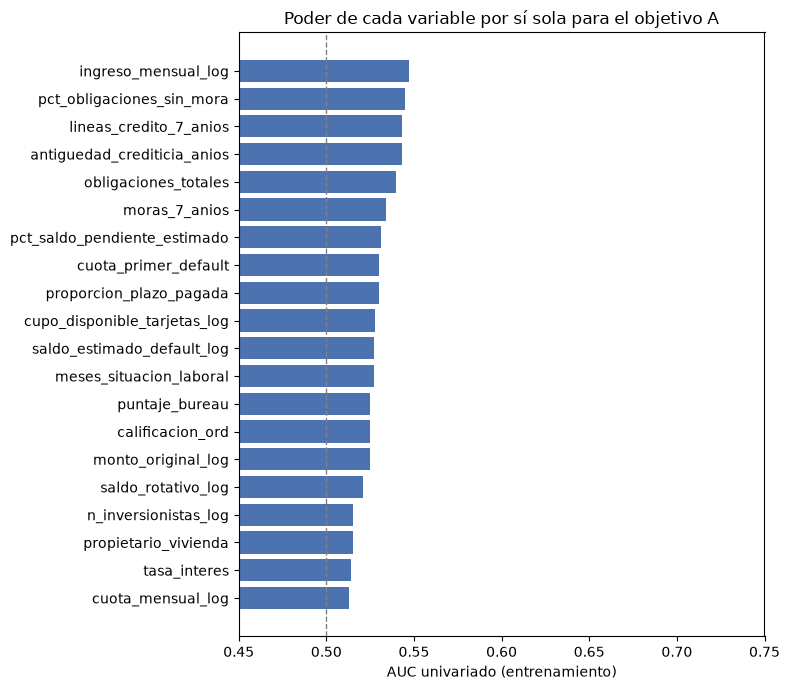

,variable,auc,direccion,pct_con_dato,sospechosa_fuga
0,ingreso_mensual_log,0.547,+,100.0,False
1,pct_obligaciones_sin_mora,0.545,−,65.0,False
2,lineas_credito_7_anios,0.543,+,97.3,False
3,antiguedad_crediticia_anios,0.543,+,97.3,False
4,obligaciones_totales,0.540,+,65.0,False
5,moras_7_anios,0.534,+,96.0,False
6,pct_saldo_pendiente_estimado,0.531,+,100.0,False
7,cuota_primer_default,0.530,−,100.0,False
8,proporcion_plazo_pagada,0.530,−,100.0,False
9,cupo_disponible_tarjetas_log,0.528,−,65.0,False


In [7]:
auc = auc_univariado(X_mod[es_ent.values], base.loc[modelado, 'objetivo_a'][es_ent.values])
print('Variables sospechosas de fuga:', auc['sospechosa_fuga'].sum())

fig, ax = plt.subplots(figsize=(8, 7))
top = auc.head(20).iloc[::-1]
ax.barh(top['variable'], top['auc'], color='#4C72B0')
ax.axvline(0.5, color='gray', ls='--', lw=1)
ax.set_xlim(0.45, max(0.75, top['auc'].max() + 0.02))
ax.set_xlabel('AUC univariado (entrenamiento)')
ax.set_title('Poder de cada variable por sí sola para el objetivo A')
plt.tight_layout(); fig.savefig(RUTAS['figuras'] / '05_auc_univariado.png', dpi=150, bbox_inches='tight'); plt.show()
auc.head(20)

## 8. Selección final de variables
Se descartan, con una razón documentada:
- Variables **de una sola época** o con etiquetas que cambian (control de la sección 5).
- Variables **sin variación** en la población de modelado.
- Variables que se evaluaron y no se incluyen por diseño (lista fija abajo).

In [8]:
excluidas = {
    # Decisiones de diseño (no se construyen en construir_variables)
    'prosper_score / perdida_estimada / retorno_estimado / rendimiento_estimado':
        'Solo existen desde 2009 (una época): el modelo aprendería el año.',
    'rango_ingresos': 'Etiquetas distintas por época ("Not displayed"); se usa ingreso_mensual.',
    'plazo_meses': 'Sin variación: 99,8 % de los créditos maduros es a 36 meses (D13).',
    'tasa_apr': 'Redundante con tasa_interes.',
    'cambio_puntaje_desde_ultimo': '83 % nulos; el historial con Prosper ya se captura con otras variables.',
    'creditos_en_cobranza': 'Cuenta créditos que cayeron en mora DESPUÉS: fuga.',
    'fechas (originación, cierre, trimestre)': 'Calendario = época; la validación es temporal.',
    # Regla pre-registrada D25, activada por el control SHAP de la Fase 6
    'estado_residencia': 'Proxy de época: SHAP de "Sin dato" +0,087 vs +0,003 del resto (Fase 6); 52 categorías.',
    'ocupacion': 'Proxy de época ("Sin dato" 9,5 % vs 0,2 %) y alta cardinalidad (67 categorías); misma regla D25.',
}
for col in nulos.index[nulos['descartar']]:
    excluidas[col] = f"Diferencia de nulos entre épocas de {nulos.loc[col, 'diferencia_pp']} pp."
for _, fila in categorias[categorias['descartar']].iterrows():
    excluidas[fila['variable']] = f"Distribución distinta entre épocas (distancia {fila['distancia_tv']})."
for col in X_mod.columns:
    if X_mod[col].nunique(dropna=True) <= 1:
        excluidas[col] = 'Sin variación en la población de modelado.'

finales = [c for c in X_todas.columns if c not in excluidas]
verificar_sin_fuga(finales)
numericas = [c for c in finales if pd.api.types.is_numeric_dtype(X_todas[c])]
categoricas = [c for c in finales if c not in numericas]

print(f'Variables finales: {len(finales)}  (numéricas: {len(numericas)}, categóricas: {len(categoricas)})')
print('Categóricas:', categoricas)
print('\nExcluidas y por qué:')
for k, v in excluidas.items():
    print(f'  - {k}: {v}')

Variables finales: 33  (numéricas: 33, categóricas: 0)
Categóricas: []

Excluidas y por qué:
  - prosper_score / perdida_estimada / retorno_estimado / rendimiento_estimado: Solo existen desde 2009 (una época): el modelo aprendería el año.
  - rango_ingresos: Etiquetas distintas por época ("Not displayed"); se usa ingreso_mensual.
  - plazo_meses: Sin variación: 99,8 % de los créditos maduros es a 36 meses (D13).
  - tasa_apr: Redundante con tasa_interes.
  - cambio_puntaje_desde_ultimo: 83 % nulos; el historial con Prosper ya se captura con otras variables.
  - creditos_en_cobranza: Cuenta créditos que cayeron en mora DESPUÉS: fuga.
  - fechas (originación, cierre, trimestre): Calendario = época; la validación es temporal.
  - estado_residencia: Proxy de época: SHAP de "Sin dato" +0,087 vs +0,003 del resto (Fase 6); 52 categorías.
  - ocupacion: Proxy de época ("Sin dato" 9,5 % vs 0,2 %) y alta cardinalidad (67 categorías); misma regla D25.
  - meses_situacion_laboral: Diferencia de nu

## 9. Guardar

In [9]:
META = ['credito_id', 'deudor_id', 'loan_key', 'conjunto', 'fecha_cierre', 'monto_original',
        'exposicion_castigo', 'recuperacion_total', 'lp_costos_cobranza', 'deudor_visto_en_entrenamiento']
OBJ = ['objetivo_a', 'objetivo_b_tasa', 'objetivo_b_monto']

salida = pd.concat([base[META + OBJ], X_todas[finales]], axis=1)
salida[modelado].to_parquet(RUTAS['data_processed'] / 'modelado.parquet', index=False)
salida[base['conjunto'] == 'inmadura'].to_parquet(RUTAS['data_processed'] / 'cartera_inmadura.parquet', index=False)

guardar_contrato(RUTAS['models'] / 'variables.json', numericas, categoricas, excluidas)
nulos.to_csv(RUTAS['docs'] / 'variables_estabilidad_nulos.csv', encoding='utf-8-sig')
categorias.to_csv(RUTAS['docs'] / 'variables_estabilidad_categorias.csv', index=False, encoding='utf-8-sig')
auc.to_csv(RUTAS['docs'] / 'variables_auc_univariado.csv', index=False, encoding='utf-8-sig')

print('✅ Guardado:')
print(f"   data/processed/modelado.parquet          {modelado.sum():,} filas")
print(f"   data/processed/cartera_inmadura.parquet  {(base['conjunto'] == 'inmadura').sum():,} filas")
print('   models/variables.json, docs/variables_*.csv, docs/figuras/05_auc_univariado.png')

✅ Guardado:
   data/processed/modelado.parquet          11,706 filas
   data/processed/cartera_inmadura.parquet  5,196 filas
   models/variables.json, docs/variables_*.csv, docs/figuras/05_auc_univariado.png


## 10. Pruebas automáticas
Ejecuta las pruebas de `tests/` (lista negra anti-fuga, cálculo del saldo, unificación de categorías).

In [10]:
import subprocess
res = subprocess.run([sys.executable, '-m', 'pytest', '-q', str(RAIZ / 'tests')],
                     capture_output=True, text=True, cwd=RAIZ)
print(res.stdout[-600:] or res.stderr[-600:])

..........                                                               [100%]
10 passed in 0.82s

